# Data Cleaning & preprocessing

## Objective

The objective of this notebook is to clean and preprocess the procurement datasets by addressing missing values, standardizing formats, converting data types, and validating data quality to support accurate and meaningful analysis.

#### Importing the Liabraries

In [ ]:
import pandas as pd
import numpy as np
import os
from pathlib import Path

DATA_PATH = Path("/content/drive/MyDrive/Procurement")


### Loading the data

In [ ]:
purchase_prices = pd.read_csv(DATA_PATH / "purchase_prices.csv")
purchases = pd.read_csv(DATA_PATH / "purchases.csv")
vendor_invoice = pd.read_csv(DATA_PATH / "vendor_invoice.csv")
vendor_sales_summary = pd.read_csv(DATA_PATH / "vendor_sales_summary.csv")

#### Created Copies of Original Dataset

In [ ]:
purchases_clean = purchases.copy()
purchase_prices_clean = purchase_prices.copy()
vendor_invoice_clean = vendor_invoice.copy()
vendor_sales_summary_clean = vendor_sales_summary.copy()

#### Removing the Missing Values

In [ ]:
datasets = {
    "purchases": purchases_clean,
    "purchase_prices": purchase_prices_clean,
    "vendor_invoice": vendor_invoice_clean,
    "vendor_sales_summary": vendor_sales_summary_clean
}
for name , df in datasets.items():

         missing_summary =pd.DataFrame({
             'Missing Count' : df.isnull().sum(),
             'Missing Percentage': round((df.isnull().sum()/len(df))*100,2)
         })
         missing_summary = missing_summary[missing_summary['Missing Count'] > 0 ]

         print(f'\n{name }:')

         if len(missing_summary) > 0:
            print(missing_summary)
         else:
            print('No missing values')



purchases:
      Missing Count  Missing Percentage
Size              3                 0.0

purchase_prices:
             Missing Count  Missing Percentage
Description              1                0.01
Size                     1                0.01
Volume                   1                0.01

vendor_invoice:
          Missing Count  Missing Percentage
Approval           5169               93.25

vendor_sales_summary:
No missing values


In [ ]:
purchases_clean['Size'].fillna(purchases_clean['Size'].mode()[0],inplace=True)

/tmp/ipykernel_967/3358354314.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  purchases_clean['Size'].fillna(purchases_clean['Size'].mode()[0],inplace=True)


In [ ]:
purchase_prices_clean[
    purchase_prices_clean[['Description','Size','Volume']]
    .isnull()
    .any(axis=1)
]

,Brand,Description,Price,Size,Volume,Classification,PurchasePrice,VendorNumber,VendorName
7915,4202,NaN,0.0,NaN,NaN,1,11.19,480,BACARDI USA INC


In [ ]:
purchase_prices_clean.dropna(subset=['Description','Size','Volume'],inplace=True)

### Vender_Invoice
Approval -> 5169 Missing - 93.25%

In [ ]:
vendor_invoice_clean['Approval'].value_counts(dropna=False)

,count
Approval,
NaN,5169
Frank Delahunt,374


In [ ]:
vendor_invoice_clean.drop(columns=['Approval'],inplace=True)

In [ ]:
datasets = {
    "purchases": purchases_clean,
    "purchase_prices": purchase_prices_clean,
    "vendor_invoice": vendor_invoice_clean,
    "vendor_sales_summary": vendor_sales_summary_clean
}
print('After Cleaning :-')
for name , df in datasets.items():

         missing_summary =pd.DataFrame({
             'Missing Count' : df.isnull().sum(),
             'Missing Percentage': round((df.isnull().sum()/len(df))*100,2)
         })
         missing_summary = missing_summary[missing_summary['Missing Count'] > 0 ]

         print(f'\n{name }:')

         if len(missing_summary) > 0:
            print(missing_summary)
         else:
            print('No missing values')

After Cleaning :-

purchases:
No missing values

purchase_prices:
No missing values

vendor_invoice:
No missing values

vendor_sales_summary:
No missing values


In [ ]:
for name, df in datasets.items():
    print(f"\n{name}")
    print(df.dtypes)


purchases
InventoryId        object
Store               int64
Brand               int64
Description        object
Size               object
VendorNumber        int64
VendorName         object
PONumber            int64
PODate             object
ReceivingDate      object
InvoiceDate        object
PayDate            object
PurchasePrice     float64
Quantity            int64
Dollars           float64
Classification      int64
dtype: object

purchase_prices
Brand               int64
Description        object
Price             float64
Size               object
Volume             object
Classification      int64
PurchasePrice     float64
VendorNumber        int64
VendorName         object
dtype: object

vendor_invoice
VendorNumber      int64
VendorName       object
InvoiceDate      object
PONumber          int64
PODate           object
PayDate          object
Quantity          int64
Dollars         float64
Freight         float64
dtype: object

vendor_sales_summary
VendorNumber              

In [ ]:
for df in datasets.values():
    for col in df.columns:
        if 'date' in col.lower():
            df[col] = pd.to_datetime(df[col], errors='coerce')

In [ ]:
for name, df in datasets.items():
    print(f"\n{name}")
    print(df.select_dtypes(include=['datetime64[ns]']).columns.tolist())


purchases
['PODate', 'ReceivingDate', 'InvoiceDate', 'PayDate']

purchase_prices
[]

vendor_invoice
['InvoiceDate', 'PODate', 'PayDate']

vendor_sales_summary
[]


In [ ]:
for name, df in datasets.items():
    print(f"\n{name}")
    print(df.columns.tolist())


purchases
['InventoryId', 'Store', 'Brand', 'Description', 'Size', 'VendorNumber', 'VendorName', 'PONumber', 'PODate', 'ReceivingDate', 'InvoiceDate', 'PayDate', 'PurchasePrice', 'Quantity', 'Dollars', 'Classification']

purchase_prices
['Brand', 'Description', 'Price', 'Size', 'Volume', 'Classification', 'PurchasePrice', 'VendorNumber', 'VendorName']

vendor_invoice
['VendorNumber', 'VendorName', 'InvoiceDate', 'PONumber', 'PODate', 'PayDate', 'Quantity', 'Dollars', 'Freight']

vendor_sales_summary
['VendorNumber', 'VendorName', 'Brand', 'Description', 'PurchasePrice', 'ActualPrice', 'Volume', 'TotalPurchaseQuantity', 'TotalPurchaseDollars', 'TotalSalesQuantity', 'TotalSalesPrice', 'TotalSalesDollars', 'TotalExciseTax', 'FreightCost', 'GrossProfit', 'ProfitMargin', 'StockTurnover', 'SalestoPurchaseRatio']


### Standardize text fields of Column (VendorName)

In [ ]:
for df in datasets.values():
    if 'VendorName' in df.columns:
        df['VendorName'] = (
            df['VendorName']
            .astype(str)
            .str.strip()
            .str.title()
        )

### Checking Outliers for numeric columns



In [ ]:
for name, df in datasets.items():
    print(f"\n{name}")
    print(df.select_dtypes(include=['int64', 'float64']).columns.tolist())


purchases
['Store', 'Brand', 'VendorNumber', 'PONumber', 'PurchasePrice', 'Quantity', 'Dollars', 'Classification']

purchase_prices
['Brand', 'Price', 'Classification', 'PurchasePrice', 'VendorNumber']

vendor_invoice
['VendorNumber', 'PONumber', 'Quantity', 'Dollars', 'Freight']

vendor_sales_summary
['VendorNumber', 'Brand', 'PurchasePrice', 'ActualPrice', 'Volume', 'TotalPurchaseQuantity', 'TotalPurchaseDollars', 'TotalSalesQuantity', 'TotalSalesPrice', 'TotalSalesDollars', 'TotalExciseTax', 'FreightCost', 'GrossProfit', 'ProfitMargin', 'StockTurnover', 'SalestoPurchaseRatio']


### These are important because:

* PurchasePrice = unit cost
* Quantity = units bought
* Dollars = total spend

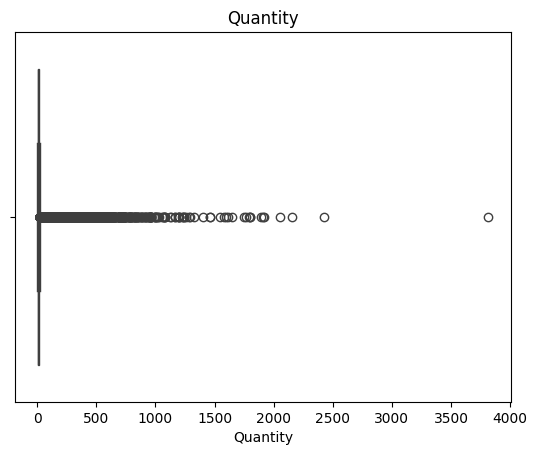

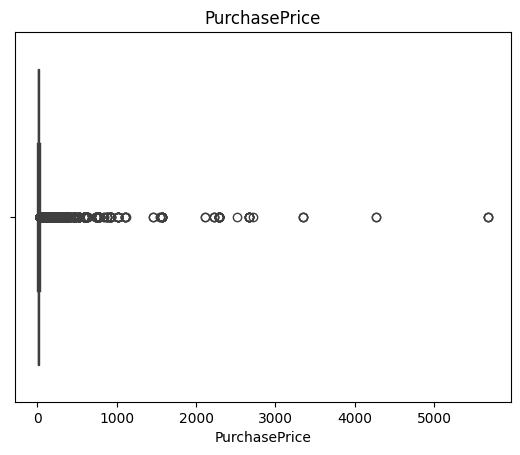

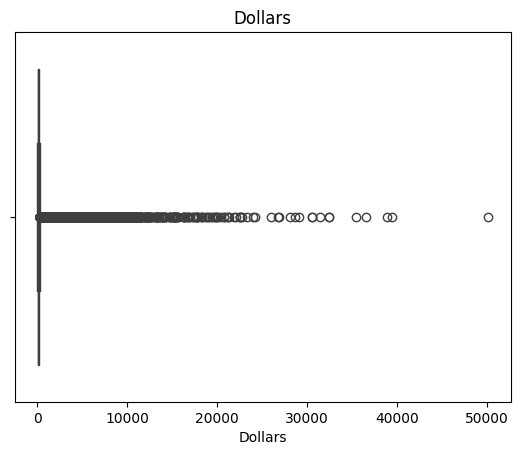

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
numeric_cols = ['Quantity', 'PurchasePrice', 'Dollars']

for col in numeric_cols:
    if col in purchases_clean.columns:
      sns.boxplot(x=purchases_clean[col])
      plt.title(col)
      plt.show()

### Saved Cleaned Dataset

In [ ]:
output_path = "/content/drive/MyDrive/Procurement/cleaned_data"

purchases_clean.to_csv(f"{output_path}/purchases_clean.csv", index=False)
purchase_prices_clean.to_csv(f"{output_path}/purchase_prices_clean.csv", index=False)
vendor_invoice_clean.to_csv(f"{output_path}/vendor_invoice_clean.csv", index=False)
vendor_sales_summary_clean.to_csv(f"{output_path}/vendor_sales_summary_clean.csv", index=False)

### **Data Cleaning Summary**
The following actions were performed:

1. Missing values were identified and treated.
2. The Approval column was removed due to excessive missingness (93.25%).
3. Date columns were converted to datetime format.
Vendor names were standardized to title case.
4. Key numerical variables were reviewed for outliers.
Cleaned datasets were generated for downstream analysis.